# End-to-end 3D: predicted masks through the cloud pipeline

The final link of chapter 3. Notebooks 05–07 measured the 3D pipeline on
**ground-truth masks**; here the masks come from the trained segmentation model
— Mask R-CNN (Detectron2, std10; the validation winner, val mask AP 0.2454) —
so the numbers describe what the *application* actually delivers.

Three configurations per matched test object, all through the identical cloud
pipeline (notebook 05):

| | mask | depth | isolates |
|---|---|---|---|
| **A** | GT | sensor | reference (= notebooks 05/07) |
| **B** | predicted | sensor | segmentation error only |
| **C** | predicted | monocular (aligned, notebook 06) | full pipeline = demo scenario |

B and C are compared against A object-by-object: Chamfer distance, centroid
offset, distance-to-camera and size/volume errors. Together with notebook 07
(depth error only, median Chamfer 10.0 cm) this factorises the total 3D error
into its two sources.

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

print("Open3D:", o3d.__version__)

Open3D: 0.19.0


In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")            # std10 config
MAP_DIR      = Path("outputs/depth_mono/maps")   # aligned monocular maps (notebook 06)
PRED_PATH    = Path("outputs/predictions/maskrcnn_detectron2_std10_test.json")
OUT_DIR      = Path("outputs/eval3d_pred")

# matching protocol — must mirror evaluate_predictions.py
CONF_THRESH = 0.5
IOU_THRESH  = 0.5

# cloud pipeline constants — must mirror notebooks 05/07 exactly
VOXEL_SIZE    = 0.02   # m
SOR_NEIGHBORS = 20
SOR_STD_RATIO = 2.0
MIN_POINTS    = 100    # per cloud; a triple is kept only if ALL three pass

MAX_DEPTH = sd.MAX_DEPTH_M   # 8 m
MIN_DEPTH = 0.3              # m

SENSOR_COLOR = "#2a78d6"     # blue   = predicted mask + sensor depth (B)
MONO_COLOR   = "#eb6834"     # orange = predicted mask + monocular depth (C)

OUT_DIR.mkdir(parents=True, exist_ok=True)
coco = COCO(str(SPLIT_DIR / "instances_test.json"))
cat_name = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}

with open(PRED_PATH) as f:
    predictions = [p for p in json.load(f) if p["score"] >= CONF_THRESH]
preds_by_img = {}
for p in predictions:
    preds_by_img.setdefault(p["image_id"], []).append(p)
print(f"Predictions with conf >= {CONF_THRESH}: {len(predictions)} "
      f"on {len(preds_by_img)} images")

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Predictions with conf >= 0.5: 5669 on 1277 images


---
## Matching and paired clouds

Predictions are matched to GT exactly as in `evaluate_predictions.py`: greedily
by descending score, class-agnostic mask IoU >= 0.5 — so a well-localised but
misclassified object still gets its 3D geometry evaluated (the
`correct_class` flag keeps the distinction). Unmatched predictions (FP) and
unmatched GT (FN) have no reference / no estimate and are counted, not
measured — the segmentation notebooks already quantify them.

All three clouds of a triple are built on the pixels valid in **both** depth
maps (as in notebook 07), so B differs from A only by the mask and C differs
from B only by the depth source.

In [3]:
def load_pair(img_info: dict):
    """Sensor depth, aligned monocular depth and intrinsics for one image."""
    d_sen = sd.read_depth(DATASET_ROOT / img_info["depth_file"])
    d_mon = np.load(MAP_DIR / f"{img_info['id']}.npy").astype(np.float32)
    intr  = sd.Intrinsics(fx=img_info["fx"], fy=img_info["fy"],
                          cx=img_info["cx"], cy=img_info["cy"])
    return d_sen, d_mon, intr


def usable(depth: np.ndarray) -> np.ndarray:
    return (depth > MIN_DEPTH) & (depth < MAX_DEPTH) & np.isfinite(depth)


def build_cloud(depth, intr, mask) -> o3d.geometry.PointCloud:
    """Back-projection + cleaning, identical to notebooks 05/07."""
    points, _ = sd.backproject(depth, intr, mask=mask)
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points.astype(np.float64))
    if len(pcd.points) == 0:
        return pcd
    pcd = pcd.voxel_down_sample(VOXEL_SIZE)
    if len(pcd.points) >= SOR_NEIGHBORS:
        pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=SOR_NEIGHBORS,
                                                std_ratio=SOR_STD_RATIO)
    return pcd


def object_3d_metrics(pcd: o3d.geometry.PointCloud) -> dict:
    pts = np.asarray(pcd.points)
    centroid = pts.mean(axis=0)
    m = {"n_points": len(pts), "centroid": centroid,
         "dist_to_camera_m": float(np.linalg.norm(centroid))}
    try:
        obb = pcd.get_oriented_bounding_box()
        m["obb_extent_1"] = sorted(obb.extent, reverse=True)[0]
        m["obb_volume_m3"] = float(np.prod(obb.extent))
    except RuntimeError:
        m["obb_extent_1"] = m["obb_volume_m3"] = np.nan
    try:
        hull, _ = pcd.compute_convex_hull()
        m["hull_volume_m3"] = float(hull.get_volume())
    except RuntimeError:
        m["hull_volume_m3"] = np.nan
    return m


def chamfer_cm(pcd_a, pcd_b) -> float:
    d_ab = np.asarray(pcd_a.compute_point_cloud_distance(pcd_b))
    d_ba = np.asarray(pcd_b.compute_point_cloud_distance(pcd_a))
    return float(100.0 * 0.5 * (d_ab.mean() + d_ba.mean()))


def pct_err(est: float, ref: float) -> float:
    if not np.isfinite(est) or not np.isfinite(ref) or ref <= 0:
        return np.nan
    return 100.0 * (est - ref) / ref


def compare_to_ref(pcd, ref_pcd, m, m_ref, prefix: str) -> dict:
    """Error metrics of one estimated cloud vs the reference cloud A."""
    return {
        f"{prefix}_chamfer_cm": chamfer_cm(pcd, ref_pcd),
        f"{prefix}_centroid_offset_cm": 100.0 * float(
            np.linalg.norm(m["centroid"] - m_ref["centroid"])),
        f"{prefix}_dist_err_m": m["dist_to_camera_m"] - m_ref["dist_to_camera_m"],
        f"{prefix}_obb_extent_1_pct_err": pct_err(m["obb_extent_1"], m_ref["obb_extent_1"]),
        f"{prefix}_obb_volume_pct_err": pct_err(m["obb_volume_m3"], m_ref["obb_volume_m3"]),
        f"{prefix}_hull_volume_pct_err": pct_err(m["hull_volume_m3"], m_ref["hull_volume_m3"]),
        f"{prefix}_n_points": m["n_points"],
    }


def match_image(img_id: int):
    """Greedy class-agnostic matching, mirroring evaluate_predictions.py."""
    gts = coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False))
    dts = sorted(preds_by_img.get(img_id, []), key=lambda p: -p["score"])
    gt_rles = [coco.annToRLE(a) for a in gts]
    dt_rles = [d["segmentation"] for d in dts]
    if not (gt_rles and dt_rles):
        return []
    ious = mask_utils.iou(dt_rles, gt_rles, [0] * len(gt_rles))
    pairs, gt_used = [], set()
    for di, d in enumerate(dts):
        best_gi, best_iou = -1, IOU_THRESH
        for gi in range(len(gts)):
            if gi not in gt_used and ious[di, gi] >= best_iou:
                best_gi, best_iou = gi, ious[di, gi]
        if best_gi >= 0:
            gt_used.add(best_gi)
            pairs.append((gts[best_gi], d, float(best_iou)))
    return pairs


def process_image(img_id: int):
    """A/B/C clouds and error metrics for every matched object of one image."""
    pairs = match_image(img_id)
    if not pairs:
        return []
    info = coco.loadImgs(img_id)[0]
    d_sen, d_mon, intr = load_pair(info)
    joint = usable(d_sen) & usable(d_mon)
    rows = []
    for gt, dt, iou in pairs:
        gt_mask = coco.annToMask(gt).astype(bool) & joint
        dt_mask = mask_utils.decode(dt["segmentation"]).astype(bool) & joint
        pcd_a = build_cloud(d_sen, intr, gt_mask)
        pcd_b = build_cloud(d_sen, intr, dt_mask)
        pcd_c = build_cloud(d_mon, intr, dt_mask)
        if min(len(pcd_a.points), len(pcd_b.points), len(pcd_c.points)) < MIN_POINTS:
            continue
        ma, mb, mc = (object_3d_metrics(p) for p in (pcd_a, pcd_b, pcd_c))
        rows.append({
            "image_id": img_id, "gt_ann_id": gt["id"],
            "class": cat_name[gt["category_id"]],
            "pred_class": cat_name[dt["category_id"]],
            "correct_class": gt["category_id"] == dt["category_id"],
            "score": dt["score"], "mask_iou": iou,
            "sensor": info["sensor"],
            "dist_ref_m": ma["dist_to_camera_m"],
            **compare_to_ref(pcd_b, pcd_a, mb, ma, "segm"),
            **compare_to_ref(pcd_c, pcd_a, mc, ma, "full"),
        })
    return rows

---
## Batch over the full test split

In [4]:
all_rows = []
t0 = time.time()
img_ids = sorted(coco.getImgIds())
for n, img_id in enumerate(img_ids, 1):
    all_rows.extend(process_image(img_id))
    if n % 50 == 0 or n == len(img_ids):
        print(f"  {n}/{len(img_ids)} images, {len(all_rows)} matched objects "
              f"({n / (time.time() - t0):.2f} img/s)", end="\r")
print()

df = pd.DataFrame(all_rows)
df.to_csv(OUT_DIR / "object_metrics_pred_masks.csv", index=False)
print(f"Matched objects with valid A/B/C clouds: {len(df)} "
      f"on {df.image_id.nunique()} images ({time.time() - t0:.0f} s)")
print(f"Correctly classified among them: {df.correct_class.mean():.1%}; "
      f"median mask IoU: {df.mask_iou.median():.3f}")

  1325/1325 images, 2772 matched objects (20.18 img/s)
Matched objects with valid A/B/C clouds: 2772 on 1118 images (66 s)
Correctly classified among them: 91.1%; median mask IoU: 0.803


---
## Summary: segmentation error vs full pipeline

`segm_*` = B vs A (predicted mask, same sensor depth); `full_*` = C vs A
(predicted mask + monocular depth). The depth-only counterpart (GT mask,
monocular depth) is notebook 07.

In [5]:
METRICS = ["chamfer_cm", "centroid_offset_cm", "dist_err_m",
           "obb_extent_1_pct_err", "obb_volume_pct_err", "hull_volume_pct_err"]

summary = pd.DataFrame({
    ("B: pred mask + sensor", "median_signed"): df[[f"segm_{m}" for m in METRICS]].median().values,
    ("B: pred mask + sensor", "median_abs"):    df[[f"segm_{m}" for m in METRICS]].abs().median().values,
    ("C: pred mask + mono",   "median_signed"): df[[f"full_{m}" for m in METRICS]].median().values,
    ("C: pred mask + mono",   "median_abs"):    df[[f"full_{m}" for m in METRICS]].abs().median().values,
}, index=METRICS).round(2)
summary.to_csv(OUT_DIR / "summary_pred_masks.csv")
summary

B: pred mask + sensor            C: pred mask + mono  \
                             median_signed median_abs       median_signed   
chamfer_cm                            1.80       1.80               10.41   
centroid_offset_cm                    7.23       7.23               19.88   
dist_err_m                           -0.01       0.04               -0.11   
obb_extent_1_pct_err                 -1.77       9.07              -19.98   
obb_volume_pct_err                  -11.80      29.00              -40.43   
hull_volume_pct_err                 -10.34      28.87              -39.67   

                                 
                     median_abs  
chamfer_cm                10.41  
centroid_offset_cm        19.88  
dist_err_m                 0.17  
obb_extent_1_pct_err      27.83  
obb_volume_pct_err        54.72  
hull_volume_pct_err       53.58

In [6]:
# breakdowns: object distance and segmentation quality drive the 3D error
df["dist_bin"] = pd.cut(df.dist_ref_m, [0, 1.5, 2.5, 3.5, 5, 8],
                        labels=["<1.5 m", "1.5–2.5 m", "2.5–3.5 m", "3.5–5 m", ">5 m"])
df["iou_bin"] = pd.cut(df.mask_iou, [0.5, 0.7, 0.85, 1.0],
                       labels=["IoU 0.5–0.7", "0.7–0.85", "0.85–1.0"])

by_distance = df.groupby("dist_bin", observed=True)[
    ["segm_chamfer_cm", "full_chamfer_cm"]].median().round(2)
by_distance["n_objects"] = df.groupby("dist_bin", observed=True).size()
by_iou = df.groupby("iou_bin", observed=True)[
    ["segm_chamfer_cm", "full_chamfer_cm"]].median().round(2)
by_iou["n_objects"] = df.groupby("iou_bin", observed=True).size()
by_class = df.groupby("class")[
    ["segm_chamfer_cm", "full_chamfer_cm", "mask_iou"]].median().round(2)
by_class["n_objects"] = df.groupby("class").size()
by_class = by_class.sort_values("full_chamfer_cm")

by_distance.to_csv(OUT_DIR / "breakdown_distance.csv")
by_iou.to_csv(OUT_DIR / "breakdown_iou.csv")
by_class.to_csv(OUT_DIR / "breakdown_class.csv")
print("By distance:"); print(by_distance, "\n")
print("By mask IoU:"); print(by_iou, "\n")
print("By class:"); print(by_class)

By distance:
           segm_chamfer_cm  full_chamfer_cm  n_objects
dist_bin                                              
<1.5 m                2.41             6.78        189
1.5–2.5 m             1.90             7.48       1189
2.5–3.5 m             1.76            12.31        793
3.5–5 m               1.62            23.87        459
>5 m                  1.40            72.36        136 

By mask IoU:
             segm_chamfer_cm  full_chamfer_cm  n_objects
iou_bin                                                 
IoU 0.5–0.7             4.03            14.09        730
0.7–0.85                1.92            11.02       1080
0.85–1.0                1.01             7.80        962 

By class:
            segm_chamfer_cm  full_chamfer_cm  mask_iou  n_objects
class                                                            
toilet                 1.24             5.94      0.89         36
desk                   2.40             8.78      0.72        121
bathtub                1.3

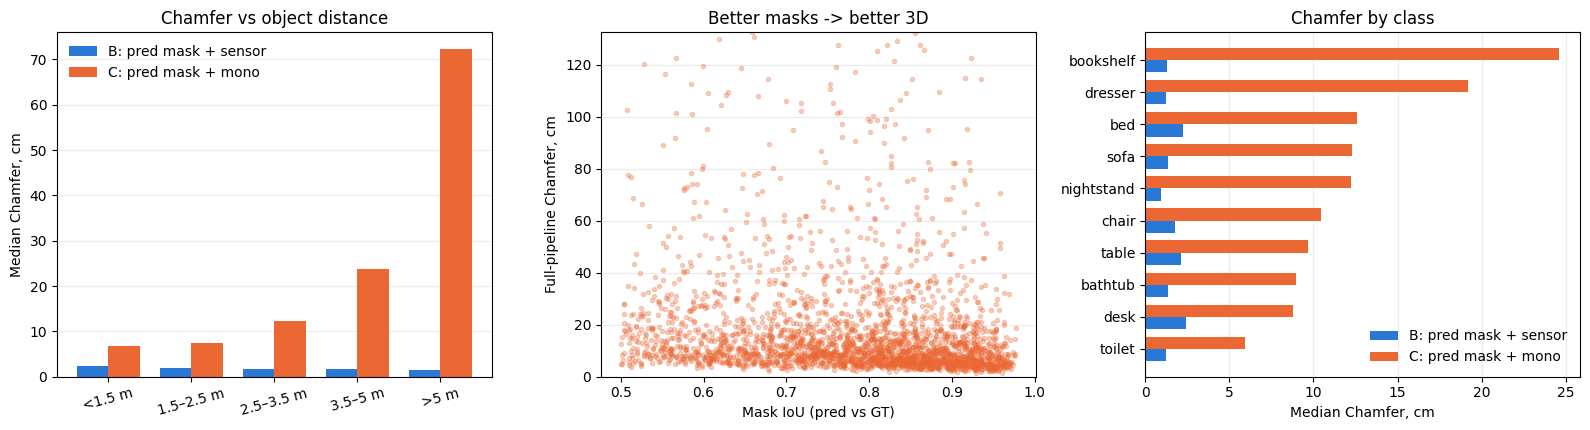

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

x = np.arange(len(by_distance))
w = 0.38
axes[0].bar(x - w / 2, by_distance.segm_chamfer_cm, w,
            color=SENSOR_COLOR, label="B: pred mask + sensor")
axes[0].bar(x + w / 2, by_distance.full_chamfer_cm, w,
            color=MONO_COLOR, label="C: pred mask + mono")
axes[0].set_xticks(x, by_distance.index, rotation=15)
axes[0].set_ylabel("Median Chamfer, cm")
axes[0].set_title("Chamfer vs object distance")
axes[0].legend(frameon=False)

axes[1].scatter(df.mask_iou, df.full_chamfer_cm, s=9, c=MONO_COLOR, alpha=0.3)
axes[1].set_xlabel("Mask IoU (pred vs GT)")
axes[1].set_ylabel("Full-pipeline Chamfer, cm")
axes[1].set_ylim(0, np.nanpercentile(df.full_chamfer_cm, 98))
axes[1].set_title("Better masks -> better 3D")

y = np.arange(len(by_class))
axes[2].barh(y - w / 2, by_class.segm_chamfer_cm, w, color=SENSOR_COLOR,
             label="B: pred mask + sensor")
axes[2].barh(y + w / 2, by_class.full_chamfer_cm, w, color=MONO_COLOR,
             label="C: pred mask + mono")
axes[2].set_yticks(y, by_class.index)
axes[2].set_xlabel("Median Chamfer, cm")
axes[2].set_title("Chamfer by class")
axes[2].legend(frameon=False)

for ax in axes:
    ax.grid(axis="x" if ax is axes[2] else "y", alpha=0.25)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "pred_masks_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Findings for chapter 3

**2772 matched objects on 1118 test images** (of 5669 predictions at
conf >= 0.5; 91.1% correctly classified, median mask IoU 0.803).

**The total 3D error factorises cleanly, and depth dominates:**

| configuration | error source | median Chamfer | median \|volume err\| |
|---|---|---|---|
| B vs A | segmentation only | **1.8 cm** | 29% |
| notebook 07 | depth only (GT masks) | 10.0 cm | 42–44% |
| C vs A | full pipeline | **10.4 cm** | 54–55% |

- **Segmentation error is almost free in 3D** — once an object is detected
  with IoU >= 0.5, replacing the GT mask with the predicted one moves the cloud
  by only ~2 cm Chamfer and ~7 cm centroid offset: boundary-pixel mistakes land
  on the same surfaces, and the shared cleaning (voxel + SOR) absorbs stray
  edge points. Volumes are more sensitive (|err| 29%) — leaked background
  pixels inflate the hull.
- **The full pipeline is depth-limited:** C ≈ notebook 07's depth-only error
  in Chamfer, and the two sources combine sub-additively. Improving the
  segmentation model would barely improve the 3D geometry of matched objects;
  improving depth (or its alignment) would.
- **B's Chamfer even *decreases* with distance** (2.4 → 1.4 cm) — a far
  object's cloud is small and coarse, so a slightly different mask changes it
  little — while C's error explodes with distance (6.8 → 72 cm), entirely
  through the depth term.
- **Mask quality still matters monotonically:** full-pipeline Chamfer improves
  from 14.1 cm (IoU 0.5–0.7) to 7.8 cm (IoU 0.85–1.0).
- **Class ranking mirrors notebook 07** (bookshelf and dresser worst, toilet
  best), confirming the depth term drives it.
- **The real cost of the segmentation model lies outside this table:** at
  conf 0.5 the detector also produces ~3.1k false positives (phantom objects
  in the 3D scene) and misses ~2.5k GT objects entirely — detection quality,
  not mask-boundary quality, is what limits the application.

---
## Notes and limitations

- **Only matched objects are measured.** FP/FN of the detector never enter the
  table — the application-level consequence (phantom objects, missed objects)
  is quantified by the P/R/F1 tables of `evaluate_predictions.py`
  (Detectron2 std10 test: TP 2561, FP 3108, FN 2527 at conf 0.5).
- **Matching is class-agnostic** (as in the evaluator); `correct_class` marks
  the ~misclassified minority among matched pairs.
- **Monocular depth uses the per-image (oracle) alignment**, as stored by
  notebook 06 — configuration C is therefore still the *best case* of the full
  pipeline; the deployable global alignment scales depth errors ~2.7×.
- **Same cleaning everywhere.** Voxel 2 cm + SOR runs identically on A, B and
  C, and all three clouds are restricted to jointly valid pixels.